# 2. Greeks

Delta and vega of a European call by three estimators: pathwise, likelihood ratio and finite differences with common random numbers. See `docs/notes/05_greeks.md` for the formulas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mc_risk.analytic import bs_delta, bs_vega, digital_delta
from mc_risk.greeks import mc_greek

pd.options.display.float_format = '{:.5f}'.format
ARGS = dict(s0=100.0, k=105.0, r=0.03, sigma=0.2, t=1.0)
Q = 0.01

In [2]:
rows = []
for greek, ref in (('delta', bs_delta(**ARGS, q=Q)), ('vega', bs_vega(**ARGS, q=Q))):
    for method in ('pathwise', 'lr', 'fd'):
        r = mc_greek(greek, method, **ARGS, q=Q, n_paths=400_000, seed=0)
        rows.append(dict(greek=greek, method=method, analytic=ref, estimate=r.price,
                         std_error=r.std_error, inside_ci=r.contains(ref)))
pd.DataFrame(rows).set_index(['greek', 'method'])

analytic  estimate  std_error  inside_ci
greek method                                            
delta pathwise   0.47767   0.47909    0.00093       True
      lr         0.47767   0.47838    0.00198       True
      fd         0.47767   0.47914    0.00092       True
vega  pathwise  39.45914  39.54795    0.11606       True
      lr        39.45914  39.44433    0.38226       True
      fd        39.45914  39.54763    0.11606       True

Pathwise and finite differences are nearly identical here (the central difference with common random numbers converges to the pathwise estimator as the bump shrinks). The likelihood ratio is unbiased too, but two to three times noisier.

## Where they separate: a digital payoff

The pathwise estimator does not exist for a discontinuous payoff. The likelihood ratio does not care. Finite differences get noisier as the bump shrinks.

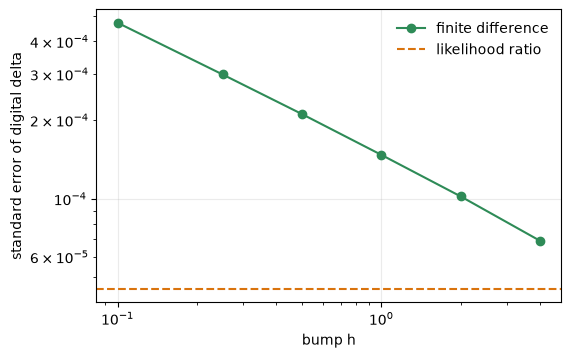

analytic 0.018790   LR 0.018839 +/- 0.000045
pathwise: pathwise estimator is not valid for a digital payoff: the payoff is discontinuous, its pathwise derivative is zero almost surely


In [3]:
ref = digital_delta(**ARGS, q=Q)
lr = mc_greek('delta', 'lr', **ARGS, payoff='digital', q=Q, n_paths=400_000, seed=0)
bumps = [4.0, 2.0, 1.0, 0.5, 0.25, 0.1]
fd = [mc_greek('delta', 'fd', **ARGS, payoff='digital', q=Q, n_paths=400_000, seed=0, bump=h) for h in bumps]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(bumps, [r.std_error for r in fd], 'o-', color='#2e8b57', label='finite difference')
ax.axhline(lr.std_error, color='#d9730d', ls='--', label='likelihood ratio')
ax.set_xlabel('bump h'); ax.set_ylabel('standard error of digital delta'); ax.legend(frameon=False); ax.grid(alpha=0.25)
plt.show()
print(f'analytic {ref:.6f}   LR {lr.price:.6f} +/- {lr.std_error:.6f}')
try:
    mc_greek('delta', 'pathwise', **ARGS, payoff='digital')
except ValueError as err:
    print('pathwise:', err)

## Why common random numbers matter

In [4]:
crn = mc_greek('delta', 'fd', **ARGS, q=Q, seed=0)
ind = mc_greek('delta', 'fd', **ARGS, q=Q, seed=0, common_random_numbers=False)
print(f'common random numbers: {crn.price:.4f} +/- {crn.std_error:.5f}')
print(f'independent draws:     {ind.price:.4f} +/- {ind.std_error:.5f}  ({(ind.std_error / crn.std_error) ** 2:,.0f}x the variance)')

common random numbers: 0.4786 +/- 0.00185
independent draws:     0.4381 +/- 0.05403  (854x the variance)
